# 06 · Estabilidad, deriva y diagnósticos

Diagnósticos que **no cambian la decisión** (definidos en la metodología del documento):
1. La caída de la mora entre cosechas y las condiciones de aprobación.
2. Efecto de cosecha: ¿cambia el nivel o el orden?
3. Sobreajuste frente a deriva.
4. Curva de aprendizaje con validación cruzada y su desviación estándar.
5. Estabilidad de las variables (PSI con línea base por azar) y prueba de fuga.
6. Cálculo de los días de mora y señales de cobranza.

Scripts: `src/06b_politica_cosechas.py`, `src/06a_diagnosticos.py` y `src/06c_mora_cobranza.py`.

In [1]:
import json, sys, importlib.util, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import protocolo as P
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 200); pd.set_option("display.float_format", "{:,.4f}".format)
R, R25, DG = P.SALIDA, P.SALIDA / "reporte_2025", P.SALIDA / "diagnosticos"
leer = lambda r: pd.read_csv(r, encoding="utf-8-sig")
def script(nombre):
    spec = importlib.util.spec_from_file_location(nombre.replace(".py", ""), RAIZ / "src" / nombre)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m
NOMBRE = {"C1_completo": "C1 · Completo (17)", "C2_seleccionado": "C2 · Seleccionado (12)",
          "C3_V2p": "C3 · Depurado (6)", "C4_V2p_compra": "C4 · C3 + compra fuera del depto. (7)",
          "C5_V3p": "C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9)", "C6_V5p": "C6 · C5 + departamento (10)",
          "A_C3_con_sexo": "C3 + sexo (7)", "segmento": "Segmento actual"}

## 1. Caída de la mora entre cosechas y condiciones de aprobación

**Población con resultado.** Los créditos que salen del panel sin deterioro son pagos anticipados y cuentan como buenos pagadores. Créditos, eventos y tasa de cada evento; proporción de los eventos a 6 meses que ya habían ocurrido a los 3 meses; y mora 30+ a 6 meses por tipo de independiente (1 = informal).

In [2]:
b = P.cargar_reporte()
filas = []
for o in ["mora30_6m", "mora60_6m", "mora90_6m", "mora30_3m"]:
    c = b[f"{o}__{P.ETIQUETA}"].dropna()
    filas.append({"evento": o, "creditos": len(c), "eventos": int(c.sum()), "tasa": c.mean()})
display(pd.DataFrame(filas))
ev6 = b[P.Y] == 1
print("Eventos a 6 meses que ya habían ocurrido a 3 meses:", round((b.loc[ev6, f"mora30_3m__{P.ETIQUETA}"] == 1).mean(), 4))
display(b[b[P.Y].notna()].groupby("independiente_informal")[P.Y].agg(creditos="count", tasa="mean"))

,evento,creditos,eventos,tasa
0,mora30_6m,2908,528,0.1816
1,mora60_6m,2904,391,0.1346
2,mora90_6m,2901,292,0.1007
3,mora30_3m,3760,354,0.0941


Eventos a 6 meses que ya habían ocurrido a 3 meses: 0.6155


,creditos,tasa
independiente_informal,,
0,2363,0.1701
1,545,0.2312


**¿La caída se explica por un cambio en la mezcla de clientes?** Mora 30+ a 6 meses por año de desembolso dentro de cada categoría de tipo de aprobación, tipo de independiente (1 = informal) y tipo de uso de la moto.

In [3]:
for col in ["ref_aprobacion", "independiente_informal", "tipo_uso_moto"]:
    display(b.pivot_table(index=col, columns="anio", values=P.Y, aggfunc=["count", "mean"]))

count              mean              
anio            2023  2024 2025   2023   2024   2025
ref_aprobacion                                      
AUTOMATICO       103    96   88 0.2621 0.1250 0.1023
MANUAL           425  1251  945 0.3694 0.1910 0.0889

count              mean              
anio                    2023  2024 2025   2023   2024   2025
independiente_informal                                      
0                        391  1100  872 0.3376 0.1809 0.0814
1                        137   247  161 0.3796 0.2105 0.1366

count                     mean              
anio                2023     2024     2025   2023   2024   2025
tipo_uso_moto                                                  
ATV                  NaN   1.0000      NaN    NaN 0.0000    NaN
DOBLE_PROPOSITO 131.0000 331.0000 246.0000 0.3817 0.2779 0.1138
NAKED_SPORT     128.0000 288.0000 181.0000 0.4297 0.1979 0.0939
SCOOTER         135.0000 559.0000 460.0000 0.2148 0.1431 0.0565
URBANA_TRABAJO  134.0000 168.0000 146.0000 0.3731 0.1310 0.1507

In [4]:
cosechas = script("06b_politica_cosechas.py")
cosechas.main()

           creditos  mora30_6m  con_resultado_6m  mora30_3m  prenda  cuota_inicial_pct  plazo_medio  plazo_48_mas  plazo_12_menos  tasa_mensual  aprobacion_automatica  segmento_oro  informal  scooter_a
trimestre                                                                                                                                                                                                
2023Q1            9     0.0000                 9     0.0000  0.0000             0.1060      42.8890        0.5560          0.0000        0.0210                 0.2220        0.0000    0.2220     0.3330
2023Q2           82     0.3660                82     0.1950  0.0000             0.2460      36.0000        0.3410          0.2200        0.0240                 0.2560        0.0980    0.2800     0.2320
2023Q3          232     0.3410               232     0.1590  0.0040             0.2640      38.8060        0.3970          0.1940        0.0260                 0.2280        0.1380    0.2630  

**Condiciones de aprobación por año de desembolso** (promedios de los trimestres ponderados por el número de créditos; 2025 incluye todo el año). Es la tabla del documento.

In [5]:
pc = leer(R / "politica_cosechas.csv")
pc["anio"] = pc["trimestre"].str[:4]
cols = ["prenda", "cuota_inicial_pct", "plazo_48_mas", "plazo_12_menos", "tasa_mensual", "aprobacion_automatica"]
pc.groupby("anio").apply(lambda d: pd.Series({c: np.average(d[c], weights=d["creditos"]) for c in cols}
                                              | {"creditos": d["creditos"].sum()})).T

anio,2023,2024,2025
prenda,0.0076,0.1722,0.7894
cuota_inicial_pct,0.2286,0.2918,0.4320
plazo_48_mas,0.4678,0.4543,0.2838
plazo_12_menos,0.1648,0.1433,0.2915
tasa_mensual,0.0254,0.0216,0.0185
aprobacion_automatica,0.1951,0.0713,0.0703
creditos,528.0000,"1,347.0000","2,844.0000"


**Lectura:**
- La mora 30+ a 6 meses cae de **34,8 % (2023)** a **18,6 % (2024)** y **9,0 % (2025, enero a junio)**. El salto principal ocurre entre 2023-T4 (36,6 %) y 2024-T1 (19,2 %).
- Entre 2023 y 2025 la caída se observa dentro de todas las categorías de tipo de aprobación, tipo de independiente y tipo de uso, así que no se explica por un cambio en la mezcla de clientes (entre 2024 y 2025, solo la moto urbana de trabajo sube).
- La caída **coincide con cambios en las condiciones de aprobación** que el modelo no usa por diseño. Entre 2023 y 2025, la **prenda** pasa de 0,8 % a 78,9 % (se extiende desde 2024-T3, con 17,7 %, y llega a 90,3 % en 2025-T4); la **cuota inicial** promedio, de 22,9 % a 43,2 %; los **plazos de 48 meses o más**, de 46,8 % a 28,4 %; la **tasa** mensual, de 2,54 % a 1,85 %; y la **aprobación automática**, de 19,5 % a 7,0 %.
- Los **pagos anticipados** (salidas del panel sin deterioro) suben en 2025: a 6 meses, 17,8 % frente a 8,9 % y 10,8 %; a 3 meses, 12,0 % frente a 5,3 % y 5,5 % (p < 0,001).
- La coincidencia es descriptiva: la base no permite separar el efecto de cada cambio sobre la caída.

## 2. Efecto de cosecha: nivel frente a orden

logit(y) = a + b·logit(puntaje) + efecto fijo de año + logit(puntaje) × año. El efecto de año mide el cambio de **nivel**; la interacción, el cambio de **orden**.

In [6]:
display(leer(DG / "C_efecto_cosecha_dev.csv"))
display(leer(R25 / "efecto_cosecha_con_2025.csv"))

,prueba,lr,p,coef,ic_inf,ic_sup
0,nivel (año),47.3510,0.0000,NaN,NaN,NaN
1,orden (puntaje x año),0.2258,0.6346,NaN,NaN,NaN
2,coef Intercept,NaN,NaN,0.8629,0.2505,1.4753
3,coef C(anio)[T.2024],NaN,NaN,-0.6562,-1.3828,0.0704
4,coef lp,NaN,NaN,1.2705,0.7632,1.7778
5,coef lp:C(anio)[T.2024],NaN,NaN,0.1463,-0.4554,0.7480


,prueba,lr,gl,p
0,nivel (efecto fijo de año),122.3297,2,0.0000
1,orden (puntaje x año),0.2664,2,0.8753


**Lectura:** el **nivel** cambia fuertemente entre cosechas (2023–2024: p < 0,001; con 2025: p < 0,001), pero el **orden no** (interacción puntaje × año: p = 0,63 en 2023–2024 y p = 0,88 con 2025). El puntaje ordena a los clientes de forma parecida en las tres cosechas; lo que cambia es la tasa base, que se corrige recalibrando el intercepto. No haber detectado un cambio de orden no prueba que no exista, pero es lo que se espera si la caída viene de cambios que afectan a todos los clientes por igual.

## 3. Sobreajuste frente a deriva

In [7]:
a = leer(DG / "A_sobreajuste.csv"); a.insert(0, "versión", a.version.map(NOMBRE)); a

,versión,version,modelo,auc_aparente,auc_cv,optimismo
0,C3 · Depurado (6),C3_V2p,logistica,0.6589,0.6292,0.0298
1,C3 · Depurado (6),C3_V2p,scorecard,0.7105,0.5954,0.1151
2,C3 · Depurado (6),C3_V2p,random_forest,0.7177,0.6297,0.0880
3,C3 · Depurado (6),C3_V2p,lightgbm,0.6880,0.6264,0.0616
4,C3 · Depurado (6),C3_V2p,xgboost,0.6791,0.6296,0.0494
5,C3 · Depurado (6),C3_V2p,catboost,0.6974,0.6379,0.0595
6,C3 · Depurado (6),C3_V2p,ebm,0.7162,0.6385,0.0778
7,C3 · Depurado (6),C3_V2p,ensamble,0.7081,0.6368,0.0713
8,C2 · Seleccionado (12),C2_seleccionado,logistica,0.6728,0.6378,0.0350
9,C2 · Seleccionado (12),C2_seleccionado,scorecard,0.6664,0.6273,0.0391


In [8]:
b = leer(DG / "B_deriva_vs_azar.csv")
b.groupby(["version", "esquema"])["auc"].agg(["mean", "std", "count"]).rename(index=NOMBRE, level=0)

mean    std  count
version                esquema                                      
C2 · Seleccionado (12) aleatorio (mismo tamaño) 0.6193 0.0171     20
                       temporal 2023 -> 2024    0.6130    NaN      1
C3 · Depurado (6)      aleatorio (mismo tamaño) 0.6006 0.0176     20
                       temporal 2023 -> 2024    0.5829    NaN      1

**Lectura:**
- **Sobreajuste:** el ensamble de C3 tiene un AUC aparente (evaluado con los mismos créditos del ajuste) de 0,708 frente a 0,637 en la validación cruzada (el promedio de los 25 pliegues, como en la selección). El optimismo viene de los algoritmos flexibles (tarjeta WoE 0,115, random forest 0,088, EBM 0,078); la regresión logística tiene el menor (0,030). Por eso **todas las comparaciones se hacen con validación cruzada o con 2025, nunca con el ajuste**.
- **Deriva:** ajustar con 2023 y probar con 2024 da un AUC de 0,583, frente a 0,601 ± 0,018 en un conjunto de prueba aleatorio del mismo tamaño: **la deriva entre cosechas cuesta 0,018 de AUC**, un efecto distinto del sobreajuste y del ruido.

## 4. Curva de aprendizaje con validación cruzada

,version,fraccion,n,auc,de,dif_vs_C3_V2p,dif_de
0,C2 · Seleccionado (12),0.2500,375.0000,0.6153,0.0378,0.0384,0.0250
1,C2 · Seleccionado (12),0.5000,750.0000,0.6372,0.0377,0.0172,0.0188
2,C2 · Seleccionado (12),0.7500,"1,125.0000",0.6448,0.0347,0.0161,0.0191
3,C2 · Seleccionado (12),1.0000,"1,500.0000",0.6481,0.0349,0.0165,0.0166
4,C3 · Depurado (6),0.2500,375.0000,0.5769,0.0319,NaN,NaN
5,C3 · Depurado (6),0.5000,750.0000,0.6200,0.0369,NaN,NaN
6,C3 · Depurado (6),0.7500,"1,125.0000",0.6287,0.0337,NaN,NaN
7,C3 · Depurado (6),1.0000,"1,500.0000",0.6316,0.0331,NaN,NaN


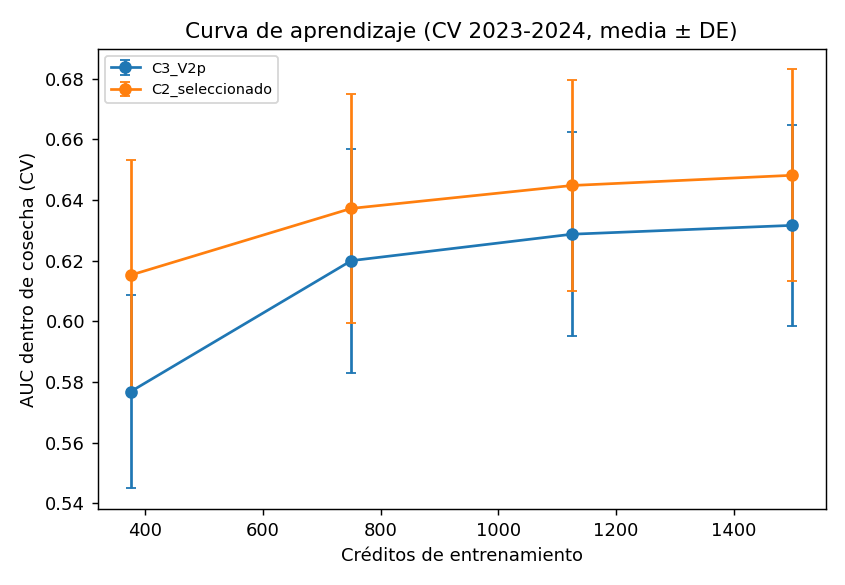

In [9]:
display(leer(DG / "D_curva_resumen.csv").assign(version=lambda d: d.version.map(NOMBRE)))
display(Image(str(DG / "D_curva_aprendizaje_cv.png")))

**Lectura:** en cada partición se entrena con el 25 %, 50 %, 75 % y 100 % del entrenamiento y se evalúa con el mismo pliegue de validación, sin tocar 2025.
- C3 sube de **0,577 ± 0,032** (375 créditos) a **0,620 ± 0,037** (750) y después se aplana: 0,629 ± 0,034 con 1.125 y 0,632 ± 0,033 con 1.500. Con los datos disponibles, ampliar la muestra de las mismas cosechas aporta poco a la discriminación.
- La ventaja de C2 sobre C3 es de +0,038, +0,017, +0,016 y +0,017 con el 25 %, el 50 %, el 75 % y el 100 % del entrenamiento, con desviaciones estándar de 0,025, 0,019, 0,019 y 0,017: **no crece con más datos y no supera dos desviaciones estándar**.

## 5. Estabilidad de las variables y prueba de fuga

In [10]:
leer(DG / "E_psi.csv")

,variable,psi_2023_2024,psi_2023_24_a_2025,azar_media,azar_p95
0,edad,0.0303,0.0033,0.0228,0.0446
1,estado_civil,0.0014,0.0106,0.0101,0.0235
2,ciudad,0.6312,0.3942,0.0645,0.1065
3,independiente_informal,0.0339,0.0140,0.0023,0.0075
4,nivel_estudio,0.0522,0.0133,0.0094,0.0210
5,familia_moto,0.2584,0.2600,0.0501,0.0711
6,PUNTAJE (OOF 2023-24 frente a 2025),0.0962,0.2312,NaN,NaN


**Lectura:** frente a la línea base por azar (p95), la edad y el estado civil son estables. El nivel de estudio (0,052 entre 2023 y 2024) y el tipo de independiente (0,034 y 0,014) la superan, con valores bajos. La **ciudad** (PSI 0,63 entre 2023 y 2024; 0,39 hacia 2025) y la **familia de moto** (0,26 y 0,26) cambian de mezcla mucho más de lo esperable por azar, con la mayor participación de la familia Scooter A. El PSI del puntaje hacia 2025 es 0,23.

In [11]:
leer(DG / "F_prueba_fuga.csv").groupby("modelo")["auc_etiqueta_permutada"].agg(["mean", "min", "max"])

,mean,min,max
modelo,,,
catboost,0.4835,0.4526,0.5119
ebm,0.4866,0.4626,0.5070
ensamble,0.4780,0.4611,0.4948
lightgbm,0.4880,0.4685,0.5087
logistica,0.4742,0.4612,0.4978
random_forest,0.4832,0.4627,0.5044
scorecard,0.4790,0.4437,0.4969
xgboost,0.4840,0.4564,0.4998


**Lectura:** con la etiqueta permutada al azar, el AUC de validación cruzada queda entre 0,474 y 0,488 en promedio según el algoritmo (valores individuales entre 0,444 y 0,512). La codificación por tasa del evento se calcula dentro de cada pliegue y **no filtra el resultado**.

## 6. Cálculo de los días de mora y señales de cobranza

Para descartar que la caída se deba a un cambio en la forma de calcular los días de mora o en la cobranza entre 2023 y 2025, se revisa el panel mensual (`src/06c_mora_cobranza.py`):
- **Cálculo de los días de mora**, por año del corte: si las cuotas en mora corresponden a los días de mora / 30 y cuánto suben los días de mora en un mes cuando la mora continúa.
- **Señales de cobranza**, por año de desembolso, en los primeros 6 meses: el impago de la primera cuota (ocurre antes de cualquier gestión de cobro), el paso de 1-29 días a 30 o más, la curación después de 30 días y el cobro jurídico.

In [12]:
leer(R / "mora_cobranza" / "calculo_dias_mora.csv")

,anio_corte,registros_en_mora,pct_cuotas_coherentes,meses_con_mora_que_sigue,aumento_mensual_mediano
0,2023,516,1.0000,253,31.0000
1,2024,3475,0.9971,2163,31.0000
2,2025,6023,0.9837,3861,31.0000


In [13]:
leer(R / "mora_cobranza" / "senales_cobranza.csv")

,anio_desembolso,impago_primera_cuota__n,impago_primera_cuota__tasa,rodamiento_1_29_a_30__n,rodamiento_1_29_a_30__tasa,curacion_tras_30__n,curacion_tras_30__tasa,cobro_juridico__n,cobro_juridico__tasa
0,2023,515,0.1631,391,0.4910,178,0.1629,528,0.0663
1,2024,1315,0.1483,684,0.3845,248,0.1169,1347,0.0564
2,2025,2279,0.0649,476,0.3025,91,0.1209,2844,0.0123


**Lectura:**
- **El cálculo de los días de mora es el mismo en todo el periodo:** las cuotas en mora coinciden con los días de mora / 30 en el 100 %, 99,7 % y 98,4 % de los registros de 2023, 2024 y 2025, y cuando la mora continúa los días suben 31 en un mes (mediana) en los tres años.
- **La caída de la mora empieza en la originación:** el impago de la primera cuota, que ocurre antes de cualquier gestión de cobro, baja de 16,3 % (2023) y 14,8 % (2024) a 6,5 % (2025).
- **No hay señal de una cobranza más eficaz para recuperar:** la curación después de 30 días no mejora (16,3 %, 11,7 % y 12,1 %).
- **El paso de 1-29 días a 30 o más baja** (49,1 %, 38,5 % y 30,3 %): es coherente con clientes de menor riesgo, con un entorno económico más favorable para ponerse al día y con un cobro preventivo más temprano, que con estos datos no se pueden separar.
- El cobro jurídico es menor en 2025 (1,2 % frente a 6,6 % y 5,6 %), en parte porque esos créditos llevan menos tiempo en la base.